# 🏴‍☠️ Treasure Hunter Arena — Learn Q-Learning by Playing

**Mission:** Train a robot to collect treasure, avoid traps, and reach the exit. Change the rewards, retrain, and watch how its behaviour changes.

**You already know:** `Q_table`, `get_next_state()`, `get_reward()`, exploration (20%), and the Q-learning update. We reuse the same ideas here.

**Run the cells from top to bottom.** The last section is an interactive playground. No external files or internet needed.

## 1 · The arena

| Symbol | Meaning | Rule |
|---|---|---|
| 🤖 | Start | Robot starts at top-left |
| 💎 | Treasure | Reward **once** per treasure |
| 🧱 | Wall | Cannot pass through |
| 💀 | Trap | Penalty each time entered; can leave |
| 🏁 | Exit | Ends the episode; exit reward |

**The challenge:** Is it worth taking a detour for a treasure? A high treasure reward might encourage risk; a large step penalty might encourage a fast exit.

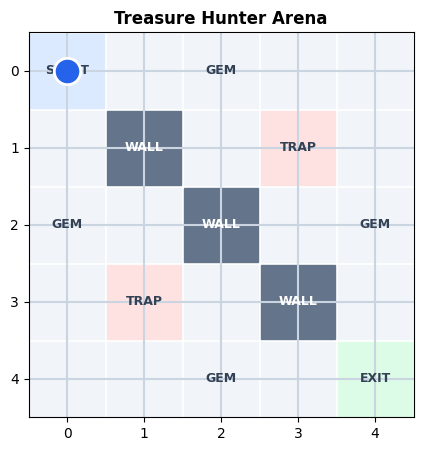

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

GRID_SIZE = 5
START = (0, 0)
GOAL = (4, 4)
WALLS = {(1, 1), (2, 2), (3, 3)}
TRAPS = {(1, 3), (3, 1)}
TREASURES = ((0, 2), (2, 0), (2, 4), (4, 2))
TREASURE_INDEX = {pos: idx for idx, pos in enumerate(TREASURES)}
ACTIONS = ('↑ Up', '↓ Down', '← Left', '→ Right')

# The same four actions as the original 4x4 grid notebook.
def get_next_state(position, action):
    i, j = position
    if action == 0: i -= 1
    elif action == 1: i += 1
    elif action == 2: j -= 1
    elif action == 3: j += 1
    candidate = (i, j)
    if not (0 <= i < GRID_SIZE and 0 <= j < GRID_SIZE) or candidate in WALLS:
        return position  # blocked move: robot stays put
    return candidate


def draw_arena(position=START, collected_mask=0, ax=None, title='Treasure Hunter Arena'):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 5))
    ax.set_xlim(-0.5, GRID_SIZE - 0.5)
    ax.set_ylim(GRID_SIZE - 0.5, -0.5)
    ax.set_xticks(range(GRID_SIZE))
    ax.set_yticks(range(GRID_SIZE))
    ax.grid(color='#cbd5e1', linewidth=1.5)
    ax.set_aspect('equal')
    for i in range(GRID_SIZE):
        for j in range(GRID_SIZE):
            cell = (i, j)
            bg = '#dbeafe' if cell == START else '#dcfce7' if cell == GOAL else '#f1f5f9'
            if cell in WALLS: bg = '#64748b'
            if cell in TRAPS: bg = '#fee2e2'
            ax.add_patch(plt.Rectangle((j-.48, i-.48), .96, .96, color=bg, zorder=0))
            label = ''
            if cell == GOAL: label = 'EXIT'
            elif cell == START: label = 'START'
            elif cell in WALLS: label = 'WALL'
            elif cell in TRAPS: label = 'TRAP'
            elif cell in TREASURE_INDEX:
                label = 'GEM' if not (collected_mask & (1 << TREASURE_INDEX[cell])) else '✓'
            if label:
                ax.text(j, i, label, ha='center', va='center', fontsize=9,
                        color='white' if cell in WALLS else '#334155', weight='bold', zorder=2)
    ax.plot(position[1], position[0], 'o', color='#2563eb', markersize=19,
            markeredgecolor='white', markeredgewidth=2, zorder=4)
    ax.set_title(title, weight='bold')
    return ax

plt.figure(figsize=(5, 5))
draw_arena(ax=plt.gca())
plt.show()

## 2 · State, action, reward — what changed?

**Original notebook:** State = `(row, column)`.

**Treasure Hunter:** State = `(row, column, collected_mask)` because the robot must remember which gems it already collected. Otherwise, it could earn points from the *same gem forever*.

- `collected_mask` is a small number encoding which of the four gems are collected (0–15).
- The **Q-table still has four actions** per state.
- `get_next_state()` still moves the robot; `get_reward()` now also considers traps, gems and the exit.

**Q-learning update stays identical:** `old_value + learning_rate * (reward + discount * next_max - old_value)`.

In [2]:
# Q-table dimensions: row × column × treasure-status × four actions
Q_table = np.zeros((GRID_SIZE, GRID_SIZE, 2 ** len(TREASURES), 4))
print('Q-table shape:', Q_table.shape)
print('Example state: (0, 0, 0) = start position, no gems collected')
print('Example state: (0, 0, 5) = gems #1 and #3 collected')

Q-table shape: (5, 5, 16, 4)
Example state: (0, 0, 0) = start position, no gems collected
Example state: (0, 0, 5) = gems #1 and #3 collected


## 3 · The learning algorithm

This is the **same loop** as your first Q-learning exercise:

1. **Choose action:** explore randomly or use `np.argmax(Q_table[state])`.
2. **Move and get reward.**
3. **Update the Q-table** using the same equation.
4. **Repeat** until exit or move limit.

Two extra rules: gems can only be collected once; the exit ends the episode. We set the future value to **0 at the exit** because there are no future moves after reaching it.

In [3]:
def get_reward(next_position, collected_mask, treasure_reward, trap_penalty,
               step_penalty, exit_reward):
    """Return (reward, updated_mask, finished)."""
    reward = step_penalty
    new_mask = collected_mask

    if next_position in TREASURE_INDEX:
        bit = 1 << TREASURE_INDEX[next_position]
        if not (collected_mask & bit):  # reward only the FIRST visit
            reward += treasure_reward
            new_mask |= bit

    if next_position in TRAPS:
        reward += trap_penalty

    finished = next_position == GOAL
    if finished:
        reward += exit_reward
    return reward, new_mask, finished


def run_episode(q_table, rng, *, training, treasure_reward, trap_penalty,
                step_penalty, exit_reward, epsilon=0.20, alpha=0.10,
                gamma=0.95, max_steps=60):
    position, collected_mask = START, 0
    path = [(position, collected_mask)]
    total_reward = 0
    for _ in range(max_steps):
        state = (position[0], position[1], collected_mask)

        # SAME exploration vs exploitation as the original notebook.
        if training and rng.random() < epsilon:
            action = rng.randrange(4)
        else:
            action = int(np.argmax(q_table[state]))

        next_position = get_next_state(position, action)
        reward, next_mask, finished = get_reward(
            next_position, collected_mask, treasure_reward,
            trap_penalty, step_penalty, exit_reward
        )
        total_reward += reward

        next_state = (next_position[0], next_position[1], next_mask)
        if training:
            old_value = q_table[state + (action,)]
            next_max = 0 if finished else np.max(q_table[next_state])
            q_table[state + (action,)] = (
                old_value + alpha * (reward + gamma * next_max - old_value)
            )

        position, collected_mask = next_position, next_mask
        path.append((position, collected_mask))
        if finished:
            break

    return {'path': path, 'score': total_reward,
            'moves': len(path)-1, 'gems': collected_mask.bit_count(),
            'reached_exit': position == GOAL}


def train_agent(treasure_reward=10, trap_penalty=-10, step_penalty=-1,
                exit_reward=15, episodes=1200, epsilon=0.20, seed=42):
    rng = random.Random(seed)
    q_table = np.zeros((GRID_SIZE, GRID_SIZE, 2 ** len(TREASURES), 4))
    scores = []
    first = None
    last = None
    for episode in range(episodes):
        result = run_episode(
            q_table, rng, training=True,
            treasure_reward=treasure_reward, trap_penalty=trap_penalty,
            step_penalty=step_penalty, exit_reward=exit_reward,
            epsilon=epsilon
        )
        scores.append(result['score'])
        if episode == 0: first = result
        if episode == episodes - 1: last = result

    # Evaluation = use learned policy only; DO NOT update Q-table.
    evaluation = run_episode(
        q_table, random.Random(seed + 1), training=False,
        treasure_reward=treasure_reward, trap_penalty=trap_penalty,
        step_penalty=step_penalty, exit_reward=exit_reward
    )
    return q_table, scores, first, last, evaluation

print('✅ Q-learning functions ready.')

✅ Q-learning functions ready.


## 4 · Interactive lab — change rewards, retrain, watch

**Try this:** Train once with the defaults. Then raise the trap penalty or treasure reward and click **Train & compare** again.

- **Episode 1** = inexperienced robot, still learning.
- **Last training episode** = experienced robot, but still 20% random moves (by default).
- **Evaluation** = trained robot using only its best-known actions, with **no random moves**.

Use the **▶ Play** button to watch all three move simultaneously. The timeline is *move number*, not real-world time. A stopped robot remains in its final position.

In [4]:
# Controls — change these without editing the algorithm above.
treasure_w = widgets.IntSlider(value=10, min=0, max=30, step=1, description='💎 Gem', continuous_update=False)
trap_w = widgets.IntSlider(value=-10, min=-30, max=0, step=1, description='💀 Trap', continuous_update=False)
step_w = widgets.IntSlider(value=-1, min=-5, max=0, step=1, description='👣 Step', continuous_update=False)
exit_w = widgets.IntSlider(value=15, min=0, max=30, step=1, description='🏁 Exit', continuous_update=False)
episodes_w = widgets.IntSlider(value=1200, min=200, max=3000, step=200, description='Episodes', continuous_update=False)
epsilon_w = widgets.FloatSlider(value=.20, min=0, max=.50, step=.05, readout_format='.2f', description='Explore', continuous_update=False)
train_button = widgets.Button(description='Train & compare', button_style='success', icon='play')

play = widgets.Play(value=0, min=0, max=60, step=1, interval=300, description='Play')
frame_slider = widgets.IntSlider(value=0, min=0, max=60, description='Move', continuous_update=False)
widgets.jslink((play, 'value'), (frame_slider, 'value'))
output = widgets.Output()
plot_output = widgets.Output()

# This stores the latest run; controls only affect the agent after retraining.
latest = {}

def show_frame(change=None):
    if not latest:
        return
    paths = [latest['first']['path'], latest['last']['path'], latest['evaluation']['path']]
    titles = ['EPISODE 1 — BEGINNER', 'LAST TRAINING EPISODE', 'EVALUATION — NO EXPLORATION']
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8))
    for ax, path, title, result in zip(axes, paths, titles,
                                      [latest['first'], latest['last'], latest['evaluation']]):
        idx = min(frame_slider.value, len(path)-1)
        position, mask = path[idx]
        draw_arena(position, mask, ax=ax, title=title)
        xs = [p[1] for p, _ in path[:idx+1]]
        ys = [p[0] for p, _ in path[:idx+1]]
        ax.plot(xs, ys, '-', color='#f97316', linewidth=2, alpha=.7, zorder=3)
        status = ('EXIT!' if result['reached_exit'] else 'TIME LIMIT') if idx == len(path)-1 else 'Moving…'
        ax.set_xlabel(f'Move {idx}/{result["moves"]} · {status}', fontsize=10)
    plt.tight_layout()
    with plot_output:
        clear_output(wait=True)
        display(fig)
    plt.close(fig)


def on_train(_):
    train_button.disabled = True
    try:
        q, scores, first, last, evaluation = train_agent(
            treasure_reward=treasure_w.value,
            trap_penalty=trap_w.value,
            step_penalty=step_w.value,
            exit_reward=exit_w.value,
            episodes=episodes_w.value,
            epsilon=epsilon_w.value,
        )
        latest.clear()
        latest.update(q=q, scores=scores, first=first, last=last, evaluation=evaluation)
        play.max = max(first['moves'], last['moves'], evaluation['moves'])
        frame_slider.max = play.max
        play.value = 0
        frame_slider.value = 0
        with output:
            clear_output(wait=True)
            print(f'✅ Trained for {episodes_w.value} episodes | exploration: {epsilon_w.value:.0%}')
            print(f'{"Run":<21} {"Moves":>6} {"Gems":>6} {"Score":>9}  Exit?')
            for name, r in [('Episode 1', first), ('Last training', last), ('Evaluation', evaluation)]:
                print(f'{name:<21} {r["moves"]:>6} {r["gems"]:>6} {r["score"]:>9.1f}  {r["reached_exit"]}')
            print('Tip: Click ▶ to play, or drag Move slider to inspect each step.')
        show_frame()
    finally:
        train_button.disabled = False

frame_slider.observe(show_frame, names='value')
train_button.on_click(on_train)

controls = widgets.VBox([
    widgets.HTML('<b>Reward settings</b>'),
    widgets.HBox([widgets.VBox([treasure_w, trap_w]), widgets.VBox([step_w, exit_w])]),
    widgets.HTML('<b>Training settings</b>'),
    widgets.HBox([episodes_w, epsilon_w]),
    train_button,
])
display(controls, output, widgets.HBox([play, frame_slider]), plot_output)
on_train(None)

Output()

Output()

### Read the results

A robot that earns more points is not always the robot that takes fewer moves. That's the lesson: **the agent optimizes the reward you gave it**, not necessarily the behaviour you imagined.

**Note:** Training is random, and tabular Q-learning may need more episodes. If the evaluation agent gets stuck or misses a gem, increase the episode count and retrain. The environment is deliberately simple so you can inspect every rule.

## 5 · Learning progress (optional)

After using the playground above, run this cell to see whether the scores improved during training. The line is a **50-episode moving average**, so it looks smoother than individual scores.

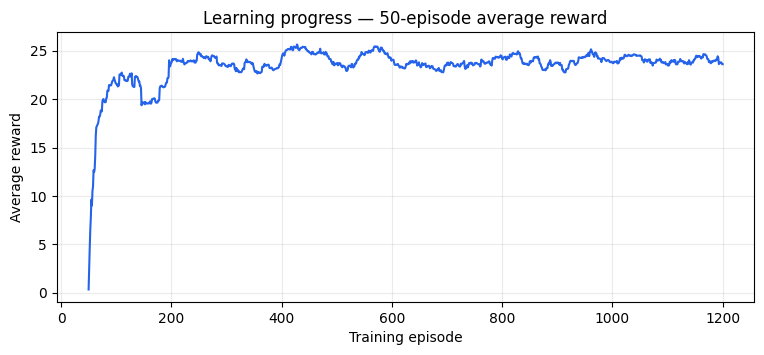

In [5]:
if not latest:
    print('Train the agent in Section 4 first.')
else:
    scores = np.asarray(latest['scores'], dtype=float)
    window = min(50, len(scores))
    moving_average = np.convolve(scores, np.ones(window)/window, mode='valid')
    plt.figure(figsize=(9, 3.5))
    plt.plot(np.arange(window, len(scores)+1), moving_average, color='#2563eb')
    plt.title(f'Learning progress — {window}-episode average reward')
    plt.xlabel('Training episode')
    plt.ylabel('Average reward')
    plt.grid(alpha=.25)
    plt.show()

## 6 · Challenge cards — try before reading the hint

**Challenge A — Greedy treasure hunter.** Increase 💎 Gem to 30. Does the agent collect more gems? What happens to the route length?

**Challenge B — Risk-averse robot.** Set 💀 Trap to −30. Does the evaluation route avoid traps? Compare its score and route.

**Challenge C — Fastest escape.** Set 💎 Gem to 0 and 👣 Step to −5. Does the robot go directly to the exit?

**Challenge D — Exploration.** Compare `Explore = 0.00` and `Explore = 0.30`. Why might a robot that never experiments struggle to learn?

**Bonus coding challenge:** Change the location of one wall or trap in Section 1, rerun all cells, and observe the new route.

> **Think:** Which change affects the *reward function*? Which changes the *environment*? Which changes the *learning strategy*?

## 7 · Connect back to your original notebook

| Original 4×4 Q-learning | Treasure Hunter Arena |
|---|---|
| `grid_size = 4` | `GRID_SIZE = 5` |
| `state = (row, col)` | `state = (row, col, collected_mask)` |
| `Q_table = np.zeros((4,4,4))` | `Q_table = np.zeros((5,5,16,4))` |
| `get_next_state()` | Same four directions, plus walls |
| `get_reward()` | Step + gem + trap + exit rewards |
| 20% random exploration | Adjustable `epsilon` |
| `old_value + 0.1 * (reward + 0.95 * next_max - old_value)` | **Same Q-learning equation** |
| Goal ends episode | Exit ends episode |

**Takeaway:** Q-learning has not changed. We only made the environment, state and reward function richer.

*Implementation note:* The game has a fixed 60-move limit, and a gem pays out once per episode. The comparison uses recorded training episodes plus a separate evaluation run, with a fixed random seed for reproducibility. The visual playback does not retrain the model; use **Train & compare** after changing controls.